# Studi Kasus Machine Learning: Prediksi Dropout dan Keberhasilan Akademik Mahasiswa

## Deskripsi kasus
Proyek ini membangun model machine learning untuk mengklasifikasikan status mahasiswa menjadi `Dropout`, `Enrolled`, atau `Graduate` berdasarkan atribut akademik, demografi, dan sosial-ekonomi yang tersedia di dataset publik UCI.

Dataset berisi 4.424 data mahasiswa dan 36 fitur. Dataset berasal dari institusi pendidikan tinggi di Portugal, sehingga hasil model **tidak boleh langsung dianggap mewakili mahasiswa Indonesia**. Proyek ini untuk pembelajaran machine learning, bukan untuk mengambil keputusan akademik nyata terhadap individu.

## Tujuan
1. Memahami struktur dan distribusi dataset.
2. Melakukan preprocessing dan membagi data menjadi data latih serta data uji.
3. Melatih dan membandingkan dua algoritma klasifikasi.
4. Mengevaluasi model menggunakan accuracy, precision, recall, F1-score, dan confusion matrix.
5. Menyimpan model dan hasil evaluasi untuk dokumentasi proyek.

## 1. Import library

Library yang digunakan meliputi pandas dan NumPy untuk pengolahan data, Matplotlib dan Seaborn untuk visualisasi, serta Scikit-learn untuk preprocessing, pemodelan, dan evaluasi.

In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

print("Library berhasil diimpor.")


Library berhasil diimpor.


## 2. Memuat dataset publik


In [8]:
import pandas as pd

DATA_URL = "https://archive.ics.uci.edu/static/public/697/data.csv"

# Baca ulang dataset dengan deteksi pemisah otomatis
df = pd.read_csv(DATA_URL, sep=None, engine="python")

# Bersihkan spasi pada nama kolom
df.columns = df.columns.str.strip()

print("Ukuran dataset:", df.shape)
print("Jumlah kolom:", len(df.columns))
print("Nama kolom terakhir:", repr(df.columns[-1]))
print("Apakah Target ditemukan?", "Target" in df.columns)

display(df.head())

Ukuran dataset: (4424, 37)
Jumlah kolom: 37
Nama kolom terakhir: 'Target'
Apakah Target ditemukan? True


,﻿Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


## 3. Memahami dataset

Periksa nama kolom, tipe data, jumlah data, dan nilai kosong. Target yang digunakan adalah kolom `Target`, dengan tiga kategori: `Dropout`, `Enrolled`, dan `Graduate`.

In [6]:
print("Jumlah baris dan kolom:", df.shape)
print("\nNama kolom:")
print(df.columns.tolist())

print("\nLima data pertama:")
display(df.head())

print("\nInformasi tipe data:")
df.info()

print("\nJumlah nilai kosong per kolom (10 teratas):")
display(df.isna().sum().sort_values(ascending=False).head(10))

print("\nJumlah data duplikat:", df.duplicated().sum())


Jumlah baris dan kolom: (4424, 1)

Nama kolom:
["Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target"]

Lima data pertama:


,"Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target"
0,"1,17,5,171,1,1,122,1,19,12,5,9,127.3,1,0,0,1,1..."
1,"1,15,1,9254,1,1,160,1,1,3,3,3,142.5,1,0,0,0,1,..."
2,"1,1,5,9070,1,1,122,1,37,37,9,9,124.8,1,0,0,0,1..."
3,"1,17,2,9773,1,1,122,1,38,37,5,3,119.6,1,0,0,1,..."
4,"2,39,1,8014,0,1,100,1,37,38,9,9,141.5,0,0,0,1,..."



Informasi tipe data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 1 columns):
 #   Column                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                             

,0
"Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target",0



Jumlah data duplikat: 0


## 4. Eksplorasi data

Tahap ini melihat distribusi kelas target dan statistik ringkas. Dataset UCI menjelaskan bahwa distribusi kelas tidak seimbang, sehingga metrik evaluasi selain accuracy perlu diperhatikan.

Distribusi target:


,Jumlah
Status,
Graduate,2209
Dropout,1421
Enrolled,794


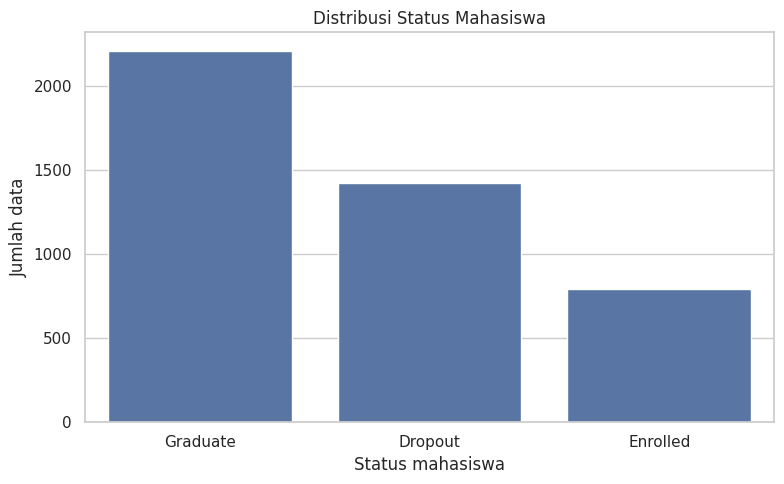

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
﻿Marital Status,4424.0,NaN,NaN,NaN,1.178571,0.605747,1.0,1.0,1.0,1.0,6.0
Application mode,4424.0,NaN,NaN,NaN,18.669078,17.484682,1.0,1.0,17.0,39.0,57.0
Application order,4424.0,NaN,NaN,NaN,1.727848,1.313793,0.0,1.0,1.0,2.0,9.0
Course,4424.0,NaN,NaN,NaN,8856.642631,2063.566416,33.0,9085.0,9238.0,9556.0,9991.0
Daytime/evening attendance,4424.0,NaN,NaN,NaN,0.890823,0.311897,0.0,1.0,1.0,1.0,1.0
Previous qualification,4424.0,NaN,NaN,NaN,4.577758,10.216592,1.0,1.0,1.0,1.0,43.0
Previous qualification (grade),4424.0,NaN,NaN,NaN,132.613314,13.188332,95.0,125.0,133.1,140.0,190.0
Nacionality,4424.0,NaN,NaN,NaN,1.873192,6.914514,1.0,1.0,1.0,1.0,109.0
Mother's qualification,4424.0,NaN,NaN,NaN,19.561935,15.603186,1.0,2.0,19.0,37.0,44.0
Father's qualification,4424.0,NaN,NaN,NaN,22.275316,15.343108,1.0,3.0,19.0,37.0,44.0


In [9]:
TARGET_COLUMN = "Target"

if TARGET_COLUMN not in df.columns:
    raise ValueError(
        f"Kolom target '{TARGET_COLUMN}' tidak ditemukan. "
        f"Kolom yang tersedia: {df.columns.tolist()}"
    )

print("Distribusi target:")
display(df[TARGET_COLUMN].value_counts().rename_axis("Status").to_frame("Jumlah"))

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x=TARGET_COLUMN, order=df[TARGET_COLUMN].value_counts().index)
plt.title("Distribusi Status Mahasiswa")
plt.xlabel("Status mahasiswa")
plt.ylabel("Jumlah data")
plt.tight_layout()
plt.show()

display(df.describe(include="all").T.head(15))


## 5. Menentukan fitur dan target

Kolom `Target` menjadi label yang diprediksi. Kolom lainnya digunakan sebagai fitur. Data pada dataset ini sebagian besar berupa nilai numerik/kode kategori yang sudah disajikan dalam format numerik oleh UCI. Untuk contoh dasar ini, semua fitur diperlakukan sebagai numerik, kemudian nilai kosong diimputasi dan fitur distandardisasi pada pipeline Logistic Regression.

In [10]:
X = df.drop(columns=[TARGET_COLUMN]).copy()
y = df[TARGET_COLUMN].astype(str).copy()

print("Jumlah fitur:", X.shape[1])
print("Jumlah sampel:", X.shape[0])
print("Kelas target:", sorted(y.unique()))
print("\nJumlah tiap kelas:")
print(y.value_counts())


Jumlah fitur: 36
Jumlah sampel: 4424
Kelas target: ['Dropout', 'Enrolled', 'Graduate']

Jumlah tiap kelas:
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


## 6. Membagi data latih dan data uji

Data dibagi menjadi 80% data latih dan 20% data uji. `stratify=y` menjaga proporsi kelas di kedua bagian agar pembagian lebih representatif terhadap distribusi kelas awal.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Data latih:", X_train.shape)
print("Data uji:", X_test.shape)
print("\nProporsi kelas pada data latih:")
print(y_train.value_counts(normalize=True).round(3))
print("\nProporsi kelas pada data uji:")
print(y_test.value_counts(normalize=True).round(3))


Data latih: (3539, 36)
Data uji: (885, 36)

Proporsi kelas pada data latih:
Target
Graduate    0.499
Dropout     0.321
Enrolled    0.179
Name: proportion, dtype: float64

Proporsi kelas pada data uji:
Target
Graduate    0.499
Dropout     0.321
Enrolled    0.180
Name: proportion, dtype: float64


## 7. Membuat pipeline dan melatih model

Dua model yang dibandingkan:

- **Logistic Regression:** model klasifikasi dasar yang dilatih dengan fitur terstandardisasi.
- **Random Forest Classifier:** gabungan beberapa pohon keputusan yang dapat mempelajari pola nonlinier.

Imputasi median dan standardisasi dilakukan dalam pipeline. Pipeline dilatih hanya pada data latih untuk menghindari kebocoran informasi dari data uji.

In [12]:
logistic_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

random_forest_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

models = {
    "Logistic Regression": logistic_pipeline,
    "Random Forest": random_forest_pipeline
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name}: selesai dilatih.")


Logistic Regression: selesai dilatih.
Random Forest: selesai dilatih.


## 8. Evaluasi model

Selain accuracy, digunakan macro precision, macro recall, dan macro F1-score. Rata-rata macro memberi bobot yang sama pada setiap kelas, sehingga performa pada kelas yang jumlahnya lebih sedikit tetap terlihat.

In [13]:
results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1-score (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values("F1-score (macro)", ascending=False)
display(results_df.round(4))


,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
1,Random Forest,0.7740,0.7307,0.6878,0.7001
0,Logistic Regression,0.7288,0.7049,0.7047,0.6927


## 9. Classification report

Classification report menampilkan precision, recall, dan F1-score untuk setiap kelas secara terpisah. Perhatikan kelas `Dropout`, `Enrolled`, dan `Graduate` agar evaluasi tidak hanya berfokus pada skor keseluruhan.

In [14]:
for name, y_pred in predictions.items():
    print("=" * 70)
    print(name)
    print("=" * 70)
    print(classification_report(y_test, y_pred, zero_division=0))


Logistic Regression
              precision    recall  f1-score   support

     Dropout       0.85      0.68      0.76       284
    Enrolled       0.41      0.64      0.50       159
    Graduate       0.86      0.79      0.82       442

    accuracy                           0.73       885
   macro avg       0.70      0.70      0.69       885
weighted avg       0.77      0.73      0.74       885

Random Forest
              precision    recall  f1-score   support

     Dropout       0.82      0.75      0.78       284
    Enrolled       0.58      0.38      0.46       159
    Graduate       0.79      0.93      0.85       442

    accuracy                           0.77       885
   macro avg       0.73      0.69      0.70       885
weighted avg       0.76      0.77      0.76       885



## 10. Confusion matrix

Confusion matrix memperlihatkan jumlah prediksi benar dan kesalahan klasifikasi pada setiap kelas. Baris menunjukkan label sebenarnya, sedangkan kolom menunjukkan label prediksi.

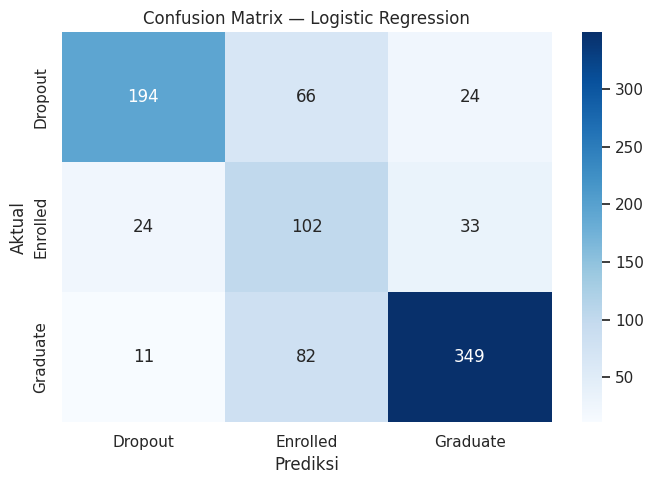

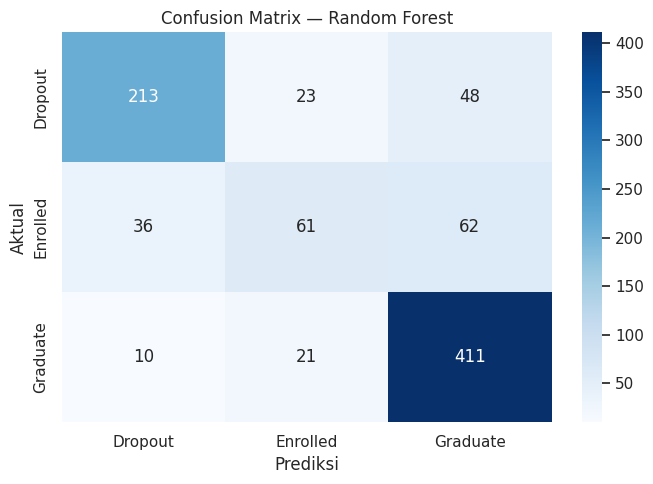

In [15]:
labels = sorted(y.unique())

for name, y_pred in predictions.items():
    cm = confusion_matrix(y_test, y_pred, labels=labels)
    plt.figure(figsize=(7, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels
    )
    plt.title(f"Confusion Matrix — {name}")
    plt.xlabel("Prediksi")
    plt.ylabel("Aktual")
    plt.tight_layout()
    plt.show()


## 11. Membandingkan performa model

Grafik berikut membandingkan empat metrik evaluasi. Nilai aktual akan muncul setelah seluruh sel sebelumnya dijalankan.

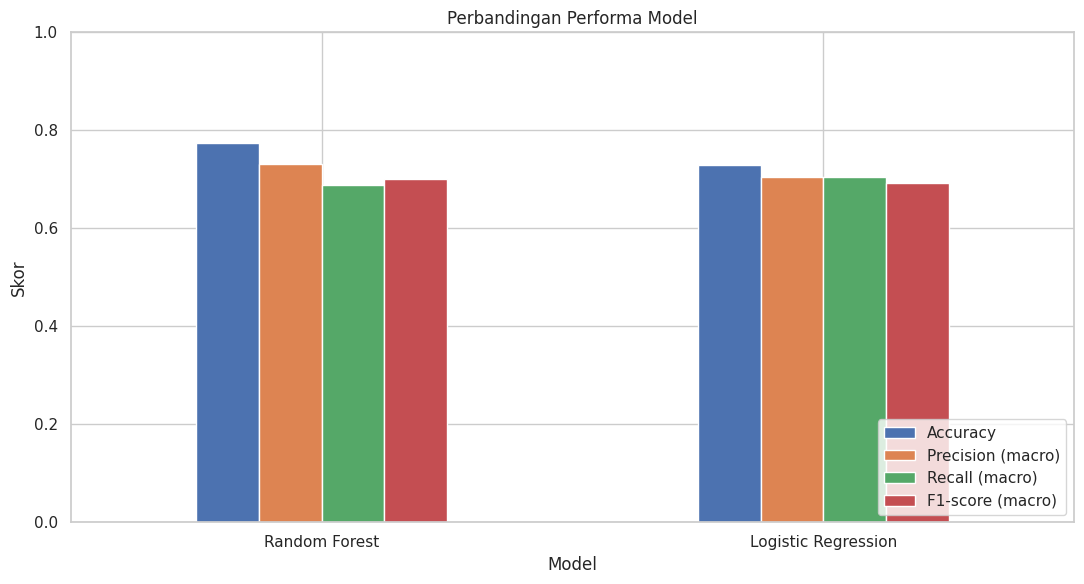

In [16]:
plot_df = results_df.set_index("Model")
plot_df.plot(kind="bar", figsize=(11, 6), ylim=(0, 1))
plt.title("Perbandingan Performa Model")
plt.ylabel("Skor")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


## 12. Melihat fitur penting dari Random Forest

Feature importance memberi gambaran fitur mana yang paling banyak berkontribusi terhadap keputusan model Random Forest. Ini bukan bukti sebab-akibat dan tidak boleh ditafsirkan sebagai alasan tunggal seorang mahasiswa mengalami dropout.

,Fitur,Importance
30,Curricular units 2nd sem (approved),0.122366
31,Curricular units 2nd sem (grade),0.096545
24,Curricular units 1st sem (approved),0.070141
25,Curricular units 1st sem (grade),0.064424
12,Admission grade,0.047101
29,Curricular units 2nd sem (evaluations),0.045082
6,Previous qualification (grade),0.042404
19,Age at enrollment,0.042298
23,Curricular units 1st sem (evaluations),0.041173
16,Tuition fees up to date,0.038329


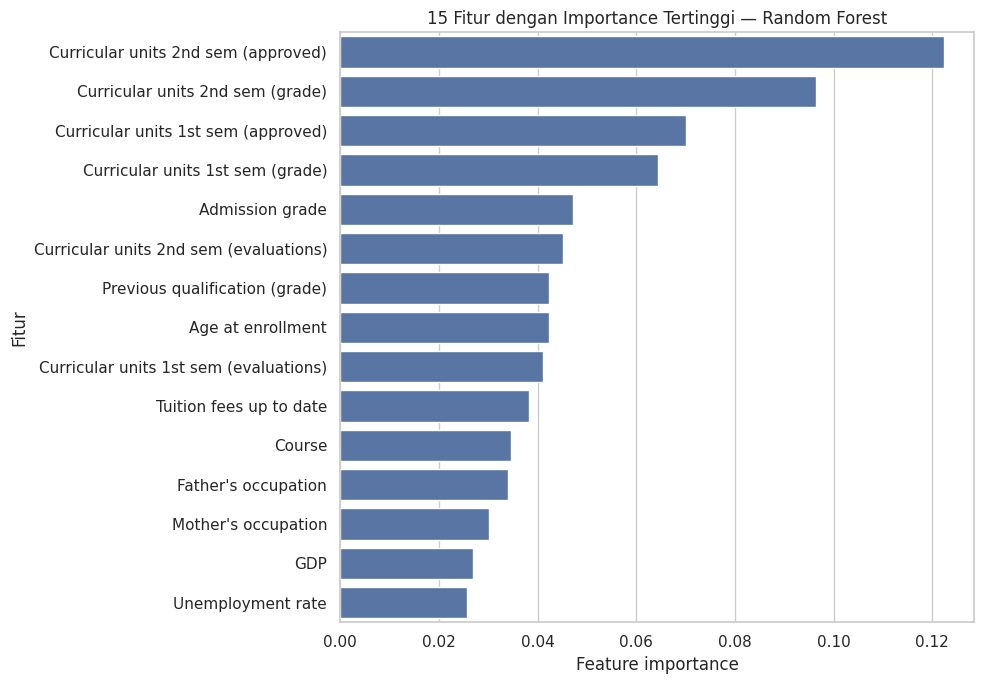

In [17]:
rf_model = models["Random Forest"].named_steps["model"]
importance_df = pd.DataFrame({
    "Fitur": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False).head(15)

display(importance_df)

plt.figure(figsize=(10, 7))
sns.barplot(data=importance_df, x="Importance", y="Fitur")
plt.title("15 Fitur dengan Importance Tertinggi — Random Forest")
plt.xlabel("Feature importance")
plt.ylabel("Fitur")
plt.tight_layout()
plt.show()


## 13. Mencoba prediksi satu data mahasiswa

Contoh berikut menggunakan satu baris dari data uji agar bentuk input sesuai dengan fitur dataset. Ini hanya demonstrasi penggunaan model, bukan penilaian nyata terhadap mahasiswa tertentu.

In [18]:
sample_student = X_test.iloc[[0]]
actual_status = y_test.iloc[0]

print("Status aktual:", actual_status)
display(sample_student.T.rename(columns={sample_student.index[0]: "Nilai fitur"}))

for name, model in models.items():
    predicted_status = model.predict(sample_student)[0]
    print(f"Prediksi {name}: {predicted_status}")


Status aktual: Graduate


,Nilai fitur
﻿Marital Status,1.000000
Application mode,44.000000
Application order,1.000000
Course,9003.000000
Daytime/evening attendance,1.000000
Previous qualification,39.000000
Previous qualification (grade),160.000000
Nacionality,1.000000
Mother's qualification,3.000000
Father's qualification,3.000000


Prediksi Logistic Regression: Graduate
Prediksi Random Forest: Graduate


## 14. Menyimpan model dan hasil evaluasi


In [19]:
OUTPUT_DIR = "hasil_proyek"
os.makedirs(OUTPUT_DIR, exist_ok=True)

joblib.dump(models["Logistic Regression"], os.path.join(OUTPUT_DIR, "logistic_regression.joblib"))
joblib.dump(models["Random Forest"], os.path.join(OUTPUT_DIR, "random_forest.joblib"))
results_df.to_csv(os.path.join(OUTPUT_DIR, "hasil_evaluasi.csv"), index=False)
importance_df.to_csv(os.path.join(OUTPUT_DIR, "feature_importance_random_forest.csv"), index=False)

print("File berhasil disimpan:")
print(os.listdir(OUTPUT_DIR))


File berhasil disimpan:
['logistic_regression.joblib', 'random_forest.joblib', 'hasil_evaluasi.csv', 'feature_importance_random_forest.csv']


## 15. Kesimpulan otomatis berdasarkan hasil eksperimen

Jalankan sel ini setelah evaluasi selesai. Model dengan F1-score macro tertinggi ditampilkan sebagai model terbaik **pada pembagian data uji ini**. Hasilnya bukan jaminan performa pada institusi atau kelompok mahasiswa lain.

In [20]:
best_row = results_df.iloc[0]
print("Ringkasan hasil:")
print(f"- Model dengan F1-score macro tertinggi: {best_row['Model']}")
print(f"- Accuracy: {best_row['Accuracy']:.4f}")
print(f"- Precision macro: {best_row['Precision (macro)']:.4f}")
print(f"- Recall macro: {best_row['Recall (macro)']:.4f}")
print(f"- F1-score macro: {best_row['F1-score (macro)']:.4f}")

print("\nCatatan:")
print("- Hasil bergantung pada pembagian data dan konfigurasi model.")
print("- Dataset berasal dari institusi pendidikan tinggi di Portugal.")
print("- Model ini ditujukan untuk pembelajaran, bukan keputusan akademik otomatis.")


Ringkasan hasil:
- Model dengan F1-score macro tertinggi: Random Forest
- Accuracy: 0.7740
- Precision macro: 0.7307
- Recall macro: 0.6878
- F1-score macro: 0.7001

Catatan:
- Hasil bergantung pada pembagian data dan konfigurasi model.
- Dataset berasal dari institusi pendidikan tinggi di Portugal.
- Model ini ditujukan untuk pembelajaran, bukan keputusan akademik otomatis.
